In [ ]:
%matplotlib inline

from pathlib import Path

import pandas as pd
import numpy as np
from sklearn import tree, metrics
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
import matplotlib.pylab as plt

!pip install dmba
from dmba import plotDecisionTree, classificationSummary, regressionSummary, liftChart, gainsChart

!pip install graphviz
import graphviz

import seaborn as sns

!pip install pydotplus
import pydotplus

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 26.3 MB/s eta 0:00:00
Colab environment detected.


In [ ]:
# Mounting the Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Load datasets
SBA_df = pd.read_csv('/content/drive/My Drive/MSBA/MSBA BA Project/SBA_clean.csv')

In [ ]:
# Make copy first
SBA_df2 = SBA_df.copy()

# Specify which variables are category for dummy variables
SBA_df2['Region'] = SBA_df2['Region'].astype('category')
SBA_df2['Term_Category'] = SBA_df2['Term_Category'].astype('category')
SBA_df2['NewExist'] = SBA_df2['NewExist'].astype('category')
SBA_df2['FranchiseCode'] = SBA_df2['FranchiseCode'].astype('category')
SBA_df2['UrbanRural'] = SBA_df2['UrbanRural'].astype('category')
SBA_df2['RevLineCr'] = SBA_df2['RevLineCr'].astype('category')
SBA_df2['LowDoc'] = SBA_df2['LowDoc'].astype('category')
SBA_df2['Recession'] = SBA_df2['Recession'].astype('category')
SBA_df2['MIS_Status'] = SBA_df2['MIS_Status'].astype('category')
SBA_df2['Industry'] = SBA_df2['Industry'].astype('category')

# Verify
SBA_df2.dtypes

,0
NoEmp,int64
NewExist,category
FranchiseCode,category
UrbanRural,category
RevLineCr,category
LowDoc,category
DisbursementGross,float64
MIS_Status,category
SBA_Appv,float64
Industry,category


# Making Dummies and Splitting Data

Splitting data into 60/40 train and valid data. Creating dummies appropriate for classification tree. Standarization is not required.

In [ ]:
# List of variables with only two categories; we want to drop one dummy to avoid redundancy
two_option_vars = ['RevLineCr', 'LowDoc', 'FranchiseCode', 'NewExist', 'Term_Category', 'Recession']

# Loop to create dummies for variables with 2 options (drop_first=True)
for col in two_option_vars:
    SBA_df2 = pd.get_dummies(SBA_df2, columns=[col], drop_first=True, dtype=int)

# List of remaining categorical variables for which we create full dummy sets
multi_option_vars = ['Region', 'UrbanRural', 'Industry']

# Loop to create dummies for other categorical variables (drop_first=False)
for col in multi_option_vars:
    SBA_df2 = pd.get_dummies(SBA_df2, columns=[col], drop_first=False, dtype=int)

# Display the head of the dataframe to verify the changes
SBA_df2.head()

,NoEmp,DisbursementGross,MIS_Status,SBA_Appv,RevLineCr_1,LowDoc_1,FranchiseCode_1,NewExist_2.0,Term_Category_Below 10 years,Recession_1,...,Region_Southwest,Region_West,UrbanRural_0,UrbanRural_1,UrbanRural_2,Industry_Financial_and_Professional_Services,Industry_Information_Arts_and_Hospitality,Industry_Public_and_Social_Services,Industry_Resource_and_Industrial_Production,Industry_Trade_and_Logistics
0,4,60000.0,0,48000.0,0,1,0,1,1,0,...,0,0,1,0,0,0,0,0,0,1
1,2,40000.0,0,32000.0,0,1,0,1,1,0,...,0,0,1,0,0,0,1,0,0,0
2,7,287000.0,0,215250.0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,1,0,0
3,19,517000.0,0,387750.0,0,0,0,0,1,0,...,0,0,1,0,0,0,0,0,1,0
4,1,45000.0,0,36000.0,0,1,0,1,1,0,...,0,0,1,0,0,0,1,0,0,0


In [ ]:
# Split into 60/40 data
train_df, valid_df = train_test_split(SBA_df2, test_size=0.4, random_state=1)
print(train_df.shape, valid_df.shape)

(284117, 23) (189412, 23)


In [ ]:
# Split train and valid into X and y
train_X = train_df.drop(columns =['MIS_Status'],axis = 1)
train_y = train_df['MIS_Status']
valid_X = valid_df.drop(columns =['MIS_Status'],axis = 1)
valid_y = valid_df['MIS_Status']

In [ ]:
# Check first 5 rows
train_X.head()

,NoEmp,DisbursementGross,SBA_Appv,RevLineCr_1,LowDoc_1,FranchiseCode_1,NewExist_2.0,Term_Category_Below 10 years,Recession_1,Region_Midwest,...,Region_Southwest,Region_West,UrbanRural_0,UrbanRural_1,UrbanRural_2,Industry_Financial_and_Professional_Services,Industry_Information_Arts_and_Hospitality,Industry_Public_and_Social_Services,Industry_Resource_and_Industrial_Production,Industry_Trade_and_Logistics
178126,5,60900.0,30450.0,0,0,0,1,1,1,0,...,0,0,0,1,0,1,0,0,0,0
244880,2,545000.0,283400.0,0,0,0,0,0,0,1,...,0,0,0,1,0,0,0,0,0,1
141699,30,15000.0,7500.0,0,0,0,0,1,1,1,...,0,0,0,1,0,0,1,0,0,0
168395,1,25000.0,12500.0,0,0,0,0,1,1,0,...,0,1,0,1,0,0,0,0,0,1
626,2,125000.0,62500.0,0,0,0,1,1,0,0,...,0,0,0,1,0,0,1,0,0,0


In [ ]:
# Check first 5 rows
train_y.head()

,MIS_Status
178126,0
244880,0
141699,0
168395,1
626,0


# Single Tree

Due to how large the tree will be, we specified max_depth = 7 and min_samples_leaf = 50 so that the tree populates.



<Figure size 3000x5000 with 0 Axes>

In [ ]:
# Train the classification tree
singleTree = DecisionTreeClassifier(criterion="gini", max_depth=7, min_samples_leaf=50)
singleTree.fit(train_X, train_y)

class_names = list(map(str, singleTree.classes_))

# Plot the tree
plt.figure(figsize=(30,50))
plotDecisionTree(singleTree, feature_names=train_X.columns, class_names=class_names)

Run classification tree feature importance to review predictors and possibility remove some  for future models.

In [ ]:
# Finding best predictors
feature_importances = pd.DataFrame({
    'Feature': train_X.columns,
    'Importance': singleTree.feature_importances_
}).sort_values(by='Importance', ascending=False)

print(feature_importances)

                                         Feature  Importance
2                                       SBA_Appv    0.429523
14                                  UrbanRural_0    0.195660
8                                    Recession_1    0.102260
1                              DisbursementGross    0.068044
3                                    RevLineCr_1    0.046936
16                                  UrbanRural_2    0.040933
7                   Term_Category_Below 10 years    0.024764
10                              Region_Northeast    0.023481
6                                   NewExist_2.0    0.016614
9                                 Region_Midwest    0.014505
19           Industry_Public_and_Social_Services    0.010230
13                                   Region_West    0.008334
11                              Region_Southeast    0.008108
0                                          NoEmp    0.005792
18     Industry_Information_Arts_and_Hospitality    0.002281
21                  Indu

We decided to drop region and industry. We believe that the UrbanRural variable captures location and likely industry.

Saved to new CSV file for future use.

In [ ]:
# Drop Variables with low score

# Reload original SBA File
SBA_df = pd.read_csv('/content/drive/My Drive/MSBA/MSBA BA Project/SBA_clean.csv')

# Drop LowDoc, NoEmp, NewExist, FranchiseCode
SBA_df = SBA_df.drop(columns=['LowDoc', 'NoEmp', 'NewExist', 'FranchiseCode', 'Industry', 'Region'])

# Make copy first
SBA_df2 = SBA_df.copy()

# Specify which variables are category for dummy variables
SBA_df2['Term_Category'] = SBA_df2['Term_Category'].astype('category')
SBA_df2['UrbanRural'] = SBA_df2['UrbanRural'].astype('category')
SBA_df2['RevLineCr'] = SBA_df2['RevLineCr'].astype('category')
SBA_df2['Recession'] = SBA_df2['Recession'].astype('category')
SBA_df2['MIS_Status'] = SBA_df2['MIS_Status'].astype('category')

# Save to csv file called SBA_clean2 after dropping variables
SBA_df2.to_csv('/content/drive/My Drive/MSBA/MSBA BA Project/SBA_clean2.csv', index=False)

SBA_df2

,UrbanRural,RevLineCr,DisbursementGross,MIS_Status,SBA_Appv,Term_Category,Recession
0,0,0,60000.0,0,48000.0,Below 10 years,0
1,0,0,40000.0,0,32000.0,Below 10 years,0
2,0,0,287000.0,0,215250.0,Above 10 years,0
3,0,0,517000.0,0,387750.0,Below 10 years,0
4,0,0,45000.0,0,36000.0,Below 10 years,0
...,...,...,...,...,...,...,...
473524,0,1,25000.0,0,12500.0,Below 10 years,0
473525,0,0,189000.0,0,189000.0,Above 10 years,0
473526,0,0,200000.0,0,150000.0,Below 10 years,0
473527,0,1,85000.0,0,42500.0,Below 10 years,0


These will be the 7 variables we use for future models: knn, logit, neural networks, and discriminant analysis.

Resplit data to ensure dropped columns are not present.

In [ ]:
# List of variables with only two categories; we want to drop one dummy to avoid redundancy
two_option_vars = ['RevLineCr', 'Term_Category', 'Recession']

# Loop to create dummies for variables with 2 options (drop_first=True)
for col in two_option_vars:
    SBA_df2 = pd.get_dummies(SBA_df2, columns=[col], drop_first=True, dtype=int)

# List of remaining categorical variables for which we create full dummy sets
multi_option_vars = ['UrbanRural']

# Loop to create dummies for other categorical variables (drop_first=False)
for col in multi_option_vars:
    SBA_df2 = pd.get_dummies(SBA_df2, columns=[col], drop_first=False, dtype=int)
# Split into 60/40 data
train_df, valid_df = train_test_split(SBA_df2, test_size=0.4, random_state=1)
print(train_df.shape, valid_df.shape)

(284117, 9) (189412, 9)


In [ ]:
# Split train and valid into X and y
train_X = train_df.drop(columns =['MIS_Status'],axis = 1)
train_y = train_df['MIS_Status']
valid_X = valid_df.drop(columns =['MIS_Status'],axis = 1)
valid_y = valid_df['MIS_Status']
train_X.head()

,DisbursementGross,SBA_Appv,RevLineCr_1,Term_Category_Below 10 years,Recession_1,UrbanRural_0,UrbanRural_1,UrbanRural_2
178126,60900.0,30450.0,0,1,1,0,1,0
244880,545000.0,283400.0,0,0,0,0,1,0
141699,15000.0,7500.0,0,1,1,0,1,0
168395,25000.0,12500.0,0,1,1,0,1,0
626,125000.0,62500.0,0,1,0,0,1,0


In [ ]:
train_y.head()

,MIS_Status
178126,0
244880,0
141699,0
168395,1
626,0


# Best Small Tree

In [ ]:
# Use grid search to find optimized tree
class_weights = {1: 5, 0: 1}
param_grid = {
    'max_depth': [10, 15, 20, 25],
    'min_impurity_decrease': [0, 0.001, 0.005, 0.01],
    'min_samples_split': [25, 50, 75, 100],
    'min_samples_leaf': [25, 50, 100, 500],
    'class_weight': [class_weights],
}
gridSearch = GridSearchCV(DecisionTreeClassifier(random_state=1), param_grid, cv=5, n_jobs=-1)
gridSearch.fit(train_X, train_y)
print('Initial parameters: ', gridSearch.best_params_)

Initial parameters:  {'class_weight': {1: 5, 0: 1}, 'max_depth': 25, 'min_impurity_decrease': 0, 'min_samples_leaf': 25, 'min_samples_split': 25}


Final fine tuning enhance the model but to avoid overfitting. We found that if we continued to fine tune, the min sample leaf reaches 2. This will clearly creates an overfitting effect.

In [ ]:
# Fine Tune
class_weights = {1: 5, 0: 1}
param_grid = {
    'max_depth': list(range(23, 26)),
    'min_impurity_decrease': list(np.arange(0, 0.001, 0.0001)),
    'min_samples_split': list(range(23, 26)),
    'min_samples_leaf': list(range(23, 26)),
    'class_weight': [class_weights],

}
gridSearch = GridSearchCV(DecisionTreeClassifier(random_state=1), param_grid, cv=5, n_jobs=-1)
gridSearch.fit(train_X, train_y)
print('Improved parameters: ', gridSearch.best_params_)

smallclassTree = gridSearch.best_estimator_

Improved parameters:  {'class_weight': {1: 5, 0: 1}, 'max_depth': 25, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 24, 'min_samples_split': 23}


The above fine tuned parameters will be used for trees.

dot: graph is too large for cairo-renderer bitmaps. Scaling by 0.138114 to fit




<Figure size 3000x10000 with 0 Axes>

In [ ]:
# Graph Best Tree training data
smallclassTree.fit(train_X, train_y)

class_names = list(map(str, smallclassTree.classes_))

# Plot the tree
plt.figure(figsize=(30,100))
plotDecisionTree(smallclassTree, feature_names=train_X.columns, class_names=class_names)

The tree is too large due to fine tuning several times.

In [ ]:
# Finding best predictors
feature_importances = pd.DataFrame({
    'Feature': train_X.columns,
    'Importance': smallclassTree.feature_importances_
}).sort_values(by='Importance', ascending=False)

print(feature_importances)

                        Feature  Importance
5                  UrbanRural_0    0.373790
1                      SBA_Appv    0.276553
0             DisbursementGross    0.222994
4                   Recession_1    0.043564
3  Term_Category_Below 10 years    0.041677
2                   RevLineCr_1    0.024416
7                  UrbanRural_2    0.009127
6                  UrbanRural_1    0.007880


In [ ]:
tree_text = export_text(smallclassTree, feature_names=list(train_X.columns))
print(tree_text)

|--- UrbanRural_0 <= 0.50
|   |--- SBA_Appv <= 51225.00
|   |   |--- Recession_1 <= 0.50
|   |   |   |--- DisbursementGross <= 5806.00
|   |   |   |   |--- SBA_Appv <= 4125.00
|   |   |   |   |   |--- DisbursementGross <= 3992.50
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |--- DisbursementGross >  3992.50
|   |   |   |   |   |   |--- DisbursementGross <= 4991.50
|   |   |   |   |   |   |   |--- SBA_Appv <= 2475.00
|   |   |   |   |   |   |   |   |--- DisbursementGross <= 4382.50
|   |   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |   |   |--- DisbursementGross >  4382.50
|   |   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |   |--- SBA_Appv >  2475.00
|   |   |   |   |   |   |   |   |--- DisbursementGross <= 4778.00
|   |   |   |   |   |   |   |   |   |--- DisbursementGross <= 4499.00
|   |   |   |   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |   |   |   |   |--- DisbursementGross >  4499.00
|   |   |   |   |   | 

This is how to view each split for each predictor. As expected the rules are very long, meaning a lot of splitting.

Accuracy Results

In [ ]:
# y_Pred
y_pred = smallclassTree.predict(valid_X)

# Precision (Positive class is 'Acceptors')
precision = metrics.precision_score(valid_y, y_pred, pos_label=1)

# Recall (Sensitivity) or True Positive Rate
recall = metrics.recall_score(valid_y, y_pred, pos_label=1)

# F1 Score (harmonic mean of Precision and Recall)
f1 = metrics.f1_score(valid_y, y_pred, pos_label=1)

# Calculate the confusion matrix
cm = metrics.confusion_matrix(valid_y, y_pred)

# Extract True Negatives (TN), False Positives (FP), False Negatives (FN), True Positives (TP)
TN, FP, FN, TP = cm.ravel()

# Specificity (True Negative Rate)
specificity = TN / (TN + FP)

# Scores dataframe
scores = pd.DataFrame({
    'Model': ['Small Class Tree'],
    'Precision': [precision],
    'Recall': [recall],
    'F1 Score': [f1],
    'Specificity': [specificity]
})

scores

,Model,Precision,Recall,F1 Score,Specificity
0,Small Class Tree,0.33842,0.808831,0.477184,0.546832


Recall is what are focused on because we we want to ensure 1s are actually 1s. 80.8% seems to be a good score.

Accuracy:  0.6051939687031445


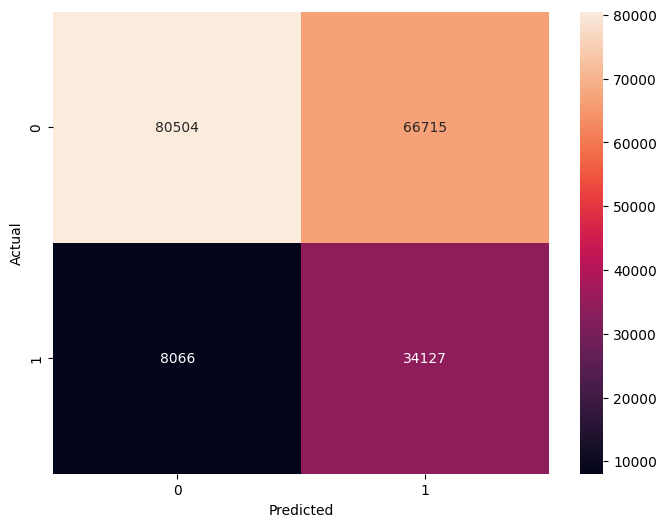

In [ ]:
#Confusion Matrix
y_pred = smallclassTree.predict(valid_X)
confusion_matrix = pd.crosstab(valid_y, y_pred, rownames=['Actual'], colnames=['Predicted'])
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, fmt='g')
print('Accuracy: ',metrics.accuracy_score(valid_y, y_pred))
plt.show()

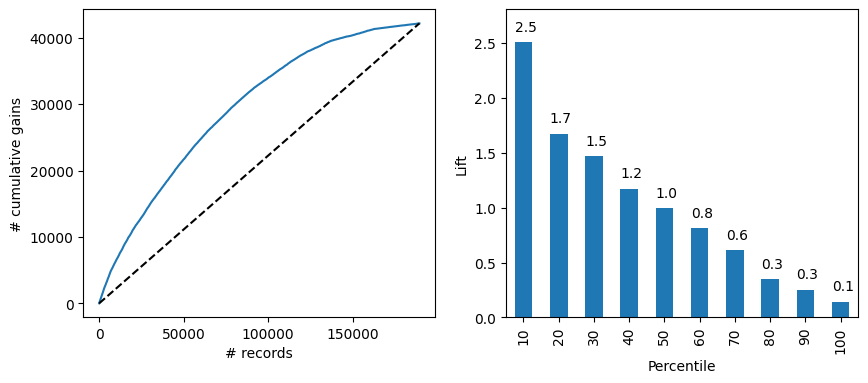

In [ ]:
# Lift and Decile Charts

# Step 1: Calculate predicted probabilities for the training set
valid_proba = smallclassTree.predict_proba(valid_X)


# Step 2: Create a DataFrame with actual, predicted probabilities, and predicted labels for the training set
valid_result = pd.DataFrame({
    'actual': valid_y,
    'p(0)': [p[0] for p in valid_proba],
    'p(1)': [p[1] for p in valid_proba],
    'predicted': smallclassTree.predict(valid_X)
})

# Step 3: Sort DataFrame by p(1)
valid_df = valid_result.sort_values(by=['p(1)'], ascending=False)

# Convert 'actual' from categorical to numeric
valid_df['actual'] = valid_df['actual'].astype(int)

# Step 4: Plot Gains and Lift charts for the training set
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

gainsChart(valid_df.actual, ax=axes[0])
liftChart(valid_df.actual, title=False)

plt.show()

Overall the model predicts 2.5 times better in the first decile. The next 20-40% bars also predict better than a random 10% of samples from the data.

Net Profit

In [ ]:
# Ensure all arrays are numpy arrays of the same shape
disbursement_gross = np.array(train_X['DisbursementGross'])
actual_y = np.array(train_y)

# Get predicted probabilities for the positive class
pred_prob = smallclassTree.predict_proba(train_X)[:, 1]  # Probabilities for class 1 ("Default")

# Initialize an array to store net profits for each threshold
thresholds = np.linspace(0.01, 0.99, 100)  # Range of thresholds from 0.01 to 0.99
net_profits = np.zeros_like(thresholds)

# Loop over each threshold and calculate the net profit
for i, threshold in enumerate(thresholds):
    # Classify based on the threshold
    pred_y = (pred_prob >= threshold).astype(int)

    # Calculate net profit based on the classification results (same logic as you provided)
    net_profit = np.zeros_like(actual_y, dtype=float)

    # Case 1: Correctly classified as "Paid in full" (Actual = 0, Predicted = 0)
    mask = (actual_y == 0) & (pred_y == 0)
    net_profit[mask] = 0.05 * disbursement_gross[mask]

    # Case 2: Incorrectly classified as "Paid in full" (Actual = 1, Predicted = 0)
    mask = (actual_y == 1) & (pred_y == 0)
    net_profit[mask] = -0.05 * disbursement_gross[mask] * 5

    # Case 3: Correctly classified as "Default" (Actual = 1, Predicted = 1)
    mask = (actual_y == 1) & (pred_y == 1)
    net_profit[mask] = 0

    # Case 4: Incorrectly classified as "Default" (Actual = 0, Predicted = 1)
    mask = (actual_y == 0) & (pred_y == 1)
    net_profit[mask] = 0  # No profit or loss for incorrect "default", adjust if necessary

    # Calculate total net profit for this threshold
    net_profits[i] = np.sum(net_profit)

# Find the threshold that maximizes the net profit
best_threshold = thresholds[np.argmax(net_profits)]
max_net_profit = np.max(net_profits)

# Output the best threshold and corresponding net profit
print(f"Best Threshold: {best_threshold:.2f}")
print(f"Maximum Net Profit: {max_net_profit:,.2f} USD")

Best Threshold: 0.50
Maximum Net Profit: 1,186,554,830.80 USD


(single tree, bagging, boosting, and random forest)

# Bagging Tree

Using the fine tuning results to supply the parameters.

In [ ]:
# Use the fine-tuned tree as the base estimator
base_estimator = DecisionTreeClassifier(
    max_depth=25,
    min_impurity_decrease=0,
    min_samples_split=23,
    min_samples_leaf=24,
    class_weight={1: 5, 0: 1},
    random_state=1
)

# Set up the BaggingClassifier with the fine-tuned base estimator
bagging = BaggingClassifier(
    estimator=base_estimator,
    n_estimators=50,  # Number of trees in the ensemble
    max_samples=0.8,  # Fraction of samples per tree
    max_features=1.0,  # Use all features for each tree
    bootstrap=True,    # Sample with replacement
    random_state=1,
    n_jobs=-1  # Use all available cores
)

# Fit the BaggingClassifier
bagging.fit(train_X, train_y)

# Evaluate the bagging model
train_score = bagging.score(train_X, train_y)
print(f"Bagging Classifier Training Accuracy: {train_score:.2f}")

Bagging Classifier Training Accuracy: 0.63


Accuracy:  0.6149927142947649


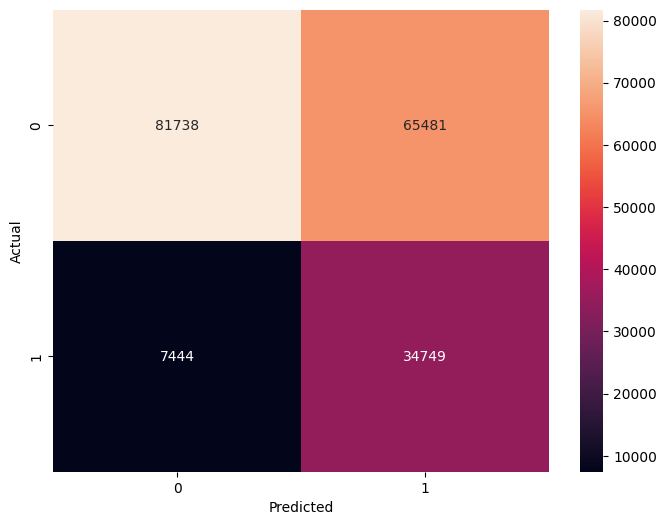

In [ ]:
#Confusion Matrix
y_pred = bagging.predict(valid_X)
confusion_matrix = pd.crosstab(valid_y, y_pred, rownames=['Actual'], colnames=['Predicted'])
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, fmt='g')
print('Accuracy: ',metrics.accuracy_score(valid_y, y_pred))
plt.show()

In [ ]:
# y_Pred
y_pred = bagging.predict(valid_X)

# Precision (Positive class is 'Acceptors')
precision = metrics.precision_score(valid_y, y_pred, pos_label=1)

# Recall (Sensitivity) or True Positive Rate
recall = metrics.recall_score(valid_y, y_pred, pos_label=1)

# F1 Score (harmonic mean of Precision and Recall)
f1 = metrics.f1_score(valid_y, y_pred, pos_label=1)

# Calculate the confusion matrix
cm = metrics.confusion_matrix(valid_y, y_pred)

# Extract True Negatives (TN), False Positives (FP), False Negatives (FN), True Positives (TP)
TN, FP, FN, TP = cm.ravel()

# Specificity (True Negative Rate)
specificity = TN / (TN + FP)

# Scores dataframe
scores = pd.DataFrame({
    'Model': ['Bagging'],
    'Precision': [precision],
    'Recall': [recall],
    'F1 Score': [f1],
    'Specificity': [specificity]
})

scores

,Model,Precision,Recall,F1 Score,Specificity
0,Bagging,0.346693,0.823573,0.487969,0.555214


Recall increased from 80% to 82%.

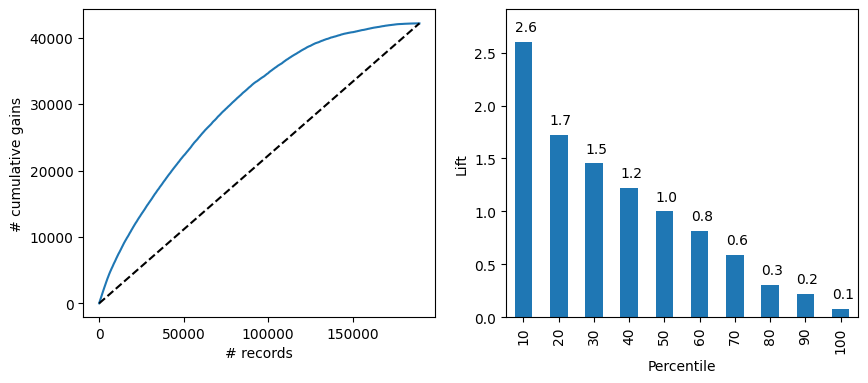

In [ ]:
# Lift and Decile Charts

# Step 1: Calculate predicted probabilities for the training set
valid_proba = bagging.predict_proba(valid_X)


# Step 2: Create a DataFrame with actual, predicted probabilities, and predicted labels for the training set
valid_result = pd.DataFrame({
    'actual': valid_y,
    'p(0)': [p[0] for p in valid_proba],
    'p(1)': [p[1] for p in valid_proba],
    'predicted': bagging.predict(valid_X)
})

# Step 3: Sort DataFrame by p(1)
valid_df = valid_result.sort_values(by=['p(1)'], ascending=False)

# Convert 'actual' from categorical to numeric
valid_df['actual'] = valid_df['actual'].astype(int)

# Step 4: Plot Gains and Lift charts for the training set
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

gainsChart(valid_df.actual, ax=axes[0])
liftChart(valid_df.actual, title=False)

plt.show()

Overall the model predicts 2.6 times better in the first decile. The next 20-40% bars also predict better than a random 10% of samples from the data.

Similar to the first tree, overall the model is good at predicting 1s, but we are more interested in making sure 1s are actually 1s.

Net Profit

In [ ]:
# Ensure all arrays are numpy arrays of the same shape
disbursement_gross = np.array(train_X['DisbursementGross'])
actual_y = np.array(train_y)

# Get predicted probabilities for the positive class
pred_prob = bagging.predict_proba(train_X)[:, 1]  # Probabilities for class 1 ("Default")

# Initialize an array to store net profits for each threshold
thresholds = np.linspace(0.01, 0.99, 100)  # Range of thresholds from 0.01 to 0.99
net_profits = np.zeros_like(thresholds)

# Loop over each threshold and calculate the net profit
for i, threshold in enumerate(thresholds):
    # Classify based on the threshold
    pred_y = (pred_prob >= threshold).astype(int)

    # Calculate net profit based on the classification results (same logic as you provided)
    net_profit = np.zeros_like(actual_y, dtype=float)

    # Case 1: Correctly classified as "Paid in full" (Actual = 0, Predicted = 0)
    mask = (actual_y == 0) & (pred_y == 0)
    net_profit[mask] = 0.05 * disbursement_gross[mask]

    # Case 2: Incorrectly classified as "Paid in full" (Actual = 1, Predicted = 0)
    mask = (actual_y == 1) & (pred_y == 0)
    net_profit[mask] = -0.05 * disbursement_gross[mask] * 5

    # Case 3: Correctly classified as "Default" (Actual = 1, Predicted = 1)
    mask = (actual_y == 1) & (pred_y == 1)
    net_profit[mask] = 0

    # Case 4: Incorrectly classified as "Default" (Actual = 0, Predicted = 1)
    mask = (actual_y == 0) & (pred_y == 1)
    net_profit[mask] = 0  # No profit or loss for incorrect "default", adjust if necessary

    # Calculate total net profit for this threshold
    net_profits[i] = np.sum(net_profit)

# Find the threshold that maximizes the net profit
best_threshold = thresholds[np.argmax(net_profits)]
max_net_profit = np.max(net_profits)

# Output the best threshold and corresponding net profit
print(f"Best Threshold: {best_threshold:.2f}")
print(f"Maximum Net Profit: {max_net_profit:,.2f} USD")

Best Threshold: 0.48
Maximum Net Profit: 1,169,842,609.15 USD


Slightly less net profit than the first tree. This is most likely becuase a few of the incorrectly classified 1s had a larger distribution gross.

# Boosting Tree

In [ ]:
# Use the fine-tuned tree as the base estimator
base_estimator = DecisionTreeClassifier(
    max_depth=25,
    min_impurity_decrease=0,
    min_samples_split=23,
    min_samples_leaf=24,
    class_weight={1: 5, 0: 1},
    random_state=1
)

# Set up the AdaBoostClassifier with the fine-tuned base estimator
boosting = AdaBoostClassifier(
    estimator=base_estimator,
    n_estimators=50,  # Number of boosting stages
    learning_rate=1.0,  # Step size shrinkage
    random_state=1,
    algorithm='SAMME'
)

# Fit the AdaBoostClassifier
boosting.fit(train_X, train_y)

# Evaluate the boosting model
train_score = boosting.score(train_X, train_y)
print(f"Boosting Classifier Training Accuracy: {train_score:.2f}")

Boosting Classifier Training Accuracy: 0.75


Accuracy:  0.6680991700631428


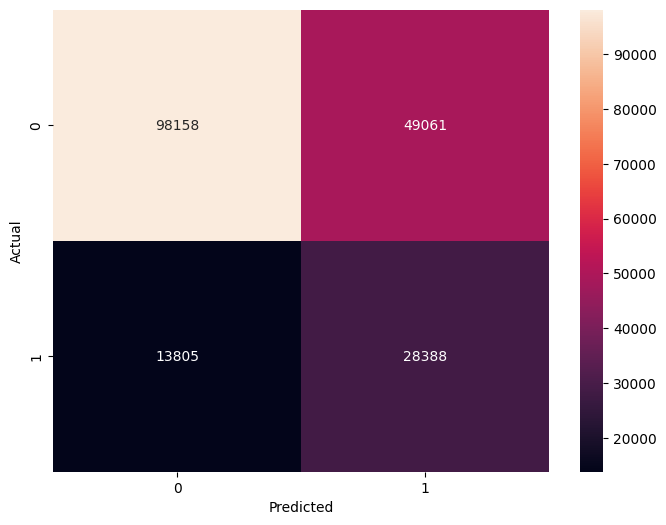

In [ ]:
#Confusion Matrix
y_pred = boosting.predict(valid_X)
confusion_matrix = pd.crosstab(valid_y, y_pred, rownames=['Actual'], colnames=['Predicted'])
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, fmt='g')
print('Accuracy: ',metrics.accuracy_score(valid_y, y_pred))
plt.show()

In [ ]:
# y_Pred
y_pred = boosting.predict(valid_X)

# Precision (Positive class is 'Acceptors')
precision = metrics.precision_score(valid_y, y_pred, pos_label=1)

# Recall (Sensitivity) or True Positive Rate
recall = metrics.recall_score(valid_y, y_pred, pos_label=1)

# F1 Score (harmonic mean of Precision and Recall)
f1 = metrics.f1_score(valid_y, y_pred, pos_label=1)

# Calculate the confusion matrix
cm = metrics.confusion_matrix(valid_y, y_pred)

# Extract True Negatives (TN), False Positives (FP), False Negatives (FN), True Positives (TP)
TN, FP, FN, TP = cm.ravel()

# Specificity (True Negative Rate)
specificity = TN / (TN + FP)

# Scores dataframe
scores = pd.DataFrame({
    'Model': ['Boosting'],
    'Precision': [precision],
    'Recall': [recall],
    'F1 Score': [f1],
    'Specificity': [specificity]
})

scores

,Model,Precision,Recall,F1 Score,Specificity
0,Boosting,0.366538,0.672813,0.474549,0.666748


The recall is worse than the first two trees.

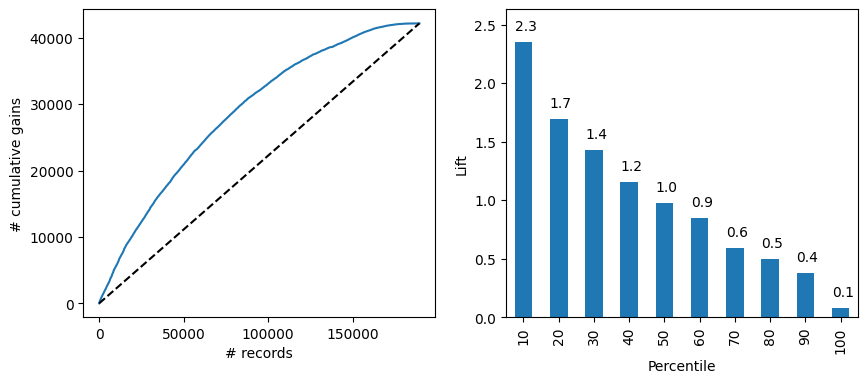

In [ ]:
# Lift and Decile Charts

# Step 1: Calculate predicted probabilities for the training set
valid_proba = boosting.predict_proba(valid_X)


# Step 2: Create a DataFrame with actual, predicted probabilities, and predicted labels for the training set
valid_result = pd.DataFrame({
    'actual': valid_y,
    'p(0)': [p[0] for p in valid_proba],
    'p(1)': [p[1] for p in valid_proba],
    'predicted': boosting.predict(valid_X)
})

# Step 3: Sort DataFrame by p(1)
valid_df = valid_result.sort_values(by=['p(1)'], ascending=False)

# Convert 'actual' from categorical to numeric
valid_df['actual'] = valid_df['actual'].astype(int)

# Step 4: Plot Gains and Lift charts for the training set
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

gainsChart(valid_df.actual, ax=axes[0])
liftChart(valid_df.actual, title=False)

plt.show()

Overall the model predicts 2.3 times better in the first decile. The next 20-40% bars also predict better than a random 10% of samples from the data.

Similar results to the bagging tree.

Net Profit

In [ ]:
# Ensure all arrays are numpy arrays of the same shape
disbursement_gross = np.array(train_X['DisbursementGross'])
actual_y = np.array(train_y)

# Get predicted probabilities for the positive class
pred_prob = boosting.predict_proba(train_X)[:, 1]  # Probabilities for class 1 ("Default")

# Initialize an array to store net profits for each threshold
thresholds = np.linspace(0.01, 0.99, 100)  # Range of thresholds from 0.01 to 0.99
net_profits = np.zeros_like(thresholds)

# Loop over each threshold and calculate the net profit
for i, threshold in enumerate(thresholds):
    # Classify based on the threshold
    pred_y = (pred_prob >= threshold).astype(int)

    # Calculate net profit based on the classification results (same logic as you provided)
    net_profit = np.zeros_like(actual_y, dtype=float)

    # Case 1: Correctly classified as "Paid in full" (Actual = 0, Predicted = 0)
    mask = (actual_y == 0) & (pred_y == 0)
    net_profit[mask] = 0.05 * disbursement_gross[mask]

    # Case 2: Incorrectly classified as "Paid in full" (Actual = 1, Predicted = 0)
    mask = (actual_y == 1) & (pred_y == 0)
    net_profit[mask] = -0.05 * disbursement_gross[mask] * 5

    # Case 3: Correctly classified as "Default" (Actual = 1, Predicted = 1)
    mask = (actual_y == 1) & (pred_y == 1)
    net_profit[mask] = 0

    # Case 4: Incorrectly classified as "Default" (Actual = 0, Predicted = 1)
    mask = (actual_y == 0) & (pred_y == 1)
    net_profit[mask] = 0  # No profit or loss for incorrect "default", adjust if necessary

    # Calculate total net profit for this threshold
    net_profits[i] = np.sum(net_profit)

# Find the threshold that maximizes the net profit
best_threshold = thresholds[np.argmax(net_profits)]
max_net_profit = np.max(net_profits)

# Output the best threshold and corresponding net profit
print(f"Best Threshold: {best_threshold:.2f}")
print(f"Maximum Net Profit: {max_net_profit:,.2f} USD")

Best Threshold: 0.50
Maximum Net Profit: 1,513,240,958.35 USD


Best net profit so far, however, given that the recall value was the worst, this would not be a good tree to use. The net profit is deteremined by the DisbursementGross, so the tree most likely predicted the 1s with higher DisbursementGross, hence the increase in net profit. Also, the model predicted a lot of correct 0s which further increase the net profit.

# Random Forest Tree

In [ ]:
# Define the class weights: Class 1 has weight 5, and Class 0 has weight 1
class_weights = {1: 5, 0: 1}

# Initialize the RandomForestClassifier with class weights
rfModel = RandomForestClassifier(
    n_estimators=100,  # Number of trees in the forest
    random_state=1,     # For reproducibility
    class_weight=class_weights  # Use the custom class weights
)

# Fit the model with training data
rfModel.fit(train_X, train_y)

# Evaluate the model
train_score = rfModel.score(train_X, train_y)
print(f"Random Forest Training Accuracy: {train_score:.2f}")

Random Forest Training Accuracy: 0.82


Accuracy:  0.6783466728612759


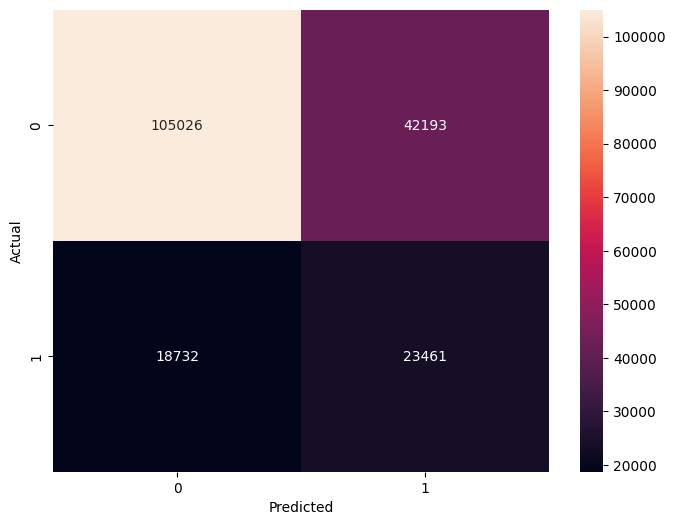

In [ ]:
#Confusion Matrix
y_pred = rfModel.predict(valid_X)
confusion_matrix = pd.crosstab(valid_y, y_pred, rownames=['Actual'], colnames=['Predicted'])
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, fmt='g')
print('Accuracy: ',metrics.accuracy_score(valid_y, y_pred))
plt.show()

In [ ]:
# y_Pred
y_pred = rfModel.predict(valid_X)

# Precision (Positive class is 'Acceptors')
precision = metrics.precision_score(valid_y, y_pred, pos_label=1)

# Recall (Sensitivity) or True Positive Rate
recall = metrics.recall_score(valid_y, y_pred, pos_label=1)

# F1 Score (harmonic mean of Precision and Recall)
f1 = metrics.f1_score(valid_y, y_pred, pos_label=1)

# Calculate the confusion matrix
cm = metrics.confusion_matrix(valid_y, y_pred)

# Extract True Negatives (TN), False Positives (FP), False Negatives (FN), True Positives (TP)
TN, FP, FN, TP = cm.ravel()

# Specificity (True Negative Rate)
specificity = TN / (TN + FP)

# Scores dataframe
scores = pd.DataFrame({
    'Model': ['RF Tree'],
    'Precision': [precision],
    'Recall': [recall],
    'F1 Score': [f1],
    'Specificity': [specificity]
})

scores

,Model,Precision,Recall,F1 Score,Specificity
0,RF Tree,0.357343,0.55604,0.435079,0.7134


Random Forest yielded the worse recall score of 55.6%. The bagging tree yielded the best recall score.

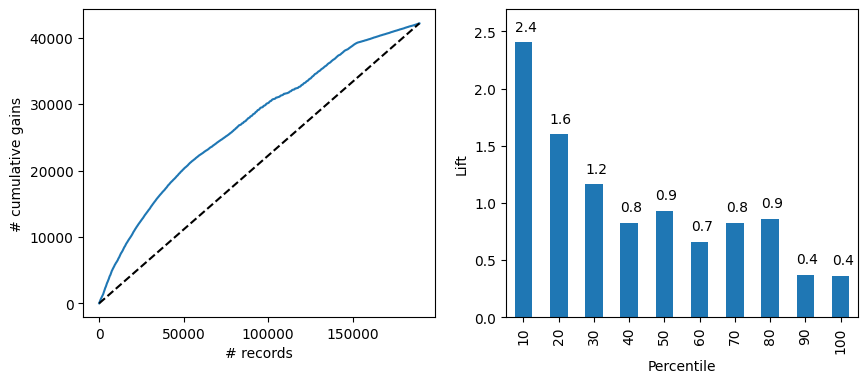

In [ ]:
# Lift and Decile Charts

# Step 1: Calculate predicted probabilities for the training set
valid_proba = rfModel.predict_proba(valid_X)


# Step 2: Create a DataFrame with actual, predicted probabilities, and predicted labels for the training set
valid_result = pd.DataFrame({
    'actual': valid_y,
    'p(0)': [p[0] for p in valid_proba],
    'p(1)': [p[1] for p in valid_proba],
    'predicted': rfModel.predict(valid_X)
})

# Step 3: Sort DataFrame by p(1)
valid_df = valid_result.sort_values(by=['p(1)'], ascending=False)

# Convert 'actual' from categorical to numeric
valid_df['actual'] = valid_df['actual'].astype(int)

# Step 4: Plot Gains and Lift charts for the training set
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

gainsChart(valid_df.actual, ax=axes[0])
liftChart(valid_df.actual, title=False)

plt.show()

Overall the model predicts 2.4 times better in the first decile. The next 20-30% bars also predict better than a random 10% of samples from the data.

The charts look worse than the bagging and boosting trees.

Net Profit

In [ ]:
# Ensure all arrays are numpy arrays of the same shape
disbursement_gross = np.array(train_X['DisbursementGross'])
actual_y = np.array(train_y)

# Get predicted probabilities for the positive class
pred_prob = rfModel.predict_proba(train_X)[:, 1]  # Probabilities for class 1 ("Default")

# Initialize an array to store net profits for each threshold
thresholds = np.linspace(0.01, 0.99, 100)  # Range of thresholds from 0.01 to 0.99
net_profits = np.zeros_like(thresholds)

# Loop over each threshold and calculate the net profit
for i, threshold in enumerate(thresholds):
    # Classify based on the threshold
    pred_y = (pred_prob >= threshold).astype(int)

    # Calculate net profit based on the classification results (same logic as you provided)
    net_profit = np.zeros_like(actual_y, dtype=float)

    # Case 1: Correctly classified as "Paid in full" (Actual = 0, Predicted = 0)
    mask = (actual_y == 0) & (pred_y == 0)
    net_profit[mask] = 0.05 * disbursement_gross[mask]

    # Case 2: Incorrectly classified as "Paid in full" (Actual = 1, Predicted = 0)
    mask = (actual_y == 1) & (pred_y == 0)
    net_profit[mask] = -0.05 * disbursement_gross[mask] * 5

    # Case 3: Correctly classified as "Default" (Actual = 1, Predicted = 1)
    mask = (actual_y == 1) & (pred_y == 1)
    net_profit[mask] = 0

    # Case 4: Incorrectly classified as "Default" (Actual = 0, Predicted = 1)
    mask = (actual_y == 0) & (pred_y == 1)
    net_profit[mask] = 0  # No profit or loss for incorrect "default", adjust if necessary

    # Calculate total net profit for this threshold
    net_profits[i] = np.sum(net_profit)

# Find the threshold that maximizes the net profit
best_threshold = thresholds[np.argmax(net_profits)]
max_net_profit = np.max(net_profits)

# Output the best threshold and corresponding net profit
print(f"Best Threshold: {best_threshold:.2f}")
print(f"Maximum Net Profit: {max_net_profit:,.2f} USD")

Best Threshold: 0.43
Maximum Net Profit: 1,689,173,283.50 USD


Even though the RF model had the worst recall, it yielded the highest net profit. This is likely to accurately predicitng 1s with high distribution gross amounts and to predicting the largest amount of true 0s (specificity).

# Best Net Profit and Cut-off

After running the various models, we looked for the model with the best recall and the model with the biggest maximum net profit.

Bagging Model

Recall: 82.36%

Max net profit $1,169,842,609.15 at 48%

RF Model

Recall: 55.60%

Max net profit $1,689,173,283.50 at 43% cut off.